# Amazon Review Sentiment Analysis

An end-to-end NLP project for classifying Amazon reviews as positive or negative.

### Techniques Used
- Text Preprocessing
- TF-IDF
- Word2Vec
- Logistic Regression
- Model Evaluation
- Confusion Matrix
- Classification Reporti

### 1.importing required libraries

In [3]:
import re
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import nltk

from nltk.corpus import stopwords
from nltk.tokenize import word_tokenize
from nltk.stem import WordNetLemmatizer

from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression

from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay
)

from gensim.models import Word2Vec

import joblib

### 2.Downloading nltk resources

In [4]:
nltk.download("punkt")
nltk.download("punkt_tab")
nltk.download("stopwords")
nltk.download("wordnet")
nltk.download("omw-1.4")

[nltk_data] Downloading package punkt to
[nltk_data]     C:\Users\BIT\AppData\Roaming\nltk_data...
[nltk_data]   Package punkt is already up-to-date!
[nltk_data] Downloading package punkt_tab to
[nltk_data]     C:\Users\BIT\AppData\Roaming\nltk_data...
[nltk_data]   Package punkt_tab is already up-to-date!
[nltk_data] Downloading package stopwords to
[nltk_data]     C:\Users\BIT\AppData\Roaming\nltk_data...
[nltk_data]   Package stopwords is already up-to-date!
[nltk_data] Downloading package wordnet to
[nltk_data]     C:\Users\BIT\AppData\Roaming\nltk_data...
[nltk_data]   Package wordnet is already up-to-date!
[nltk_data] Downloading package omw-1.4 to
[nltk_data]     C:\Users\BIT\AppData\Roaming\nltk_data...
[nltk_data]   Package omw-1.4 is already up-to-date!


True

### 3.loading the dataset

In [5]:
df = pd.read_csv("../Dataset/all_kindle_review.csv")
df.head()

,Unnamed: 0.1,Unnamed: 0,asin,helpful,rating,reviewText,reviewTime,reviewerID,reviewerName,summary,unixReviewTime
0,0,11539,B0033UV8HI,"[8, 10]",3,"Jace Rankin may be short, but he's nothing to ...","09 2, 2010",A3HHXRELK8BHQG,Ridley,Entertaining But Average,1283385600
1,1,5957,B002HJV4DE,"[1, 1]",5,Great short read. I didn't want to put it dow...,"10 8, 2013",A2RGNZ0TRF578I,Holly Butler,Terrific menage scenes!,1381190400
2,2,9146,B002ZG96I4,"[0, 0]",3,I'll start by saying this is the first of four...,"04 11, 2014",A3S0H2HV6U1I7F,Merissa,Snapdragon Alley,1397174400
3,3,7038,B002QHWOEU,"[1, 3]",3,Aggie is Angela Lansbury who carries pocketboo...,"07 5, 2014",AC4OQW3GZ919J,Cleargrace,very light murder cozy,1404518400
4,4,1776,B001A06VJ8,"[0, 1]",4,I did not expect this type of book to be in li...,"12 31, 2012",A3C9V987IQHOQD,Rjostler,Book,1356912000


In [6]:
print("Shape:", df.shape)

df.info()

Shape: (12000, 11)
<class 'pandas.DataFrame'>
RangeIndex: 12000 entries, 0 to 11999
Data columns (total 11 columns):
 #   Column          Non-Null Count  Dtype
---  ------          --------------  -----
 0   Unnamed: 0.1    12000 non-null  int64
 1   Unnamed: 0      12000 non-null  int64
 2   asin            12000 non-null  str  
 3   helpful         12000 non-null  str  
 4   rating          12000 non-null  int64
 5   reviewText      12000 non-null  str  
 6   reviewTime      12000 non-null  str  
 7   reviewerID      12000 non-null  str  
 8   reviewerName    11962 non-null  str  
 9   summary         11998 non-null  str  
 10  unixReviewTime  12000 non-null  int64
dtypes: int64(4), str(7)
memory usage: 8.8 MB


In [7]:
print(df.isnull().sum())
print("*"*10)
print(df.duplicated().sum())

Unnamed: 0.1       0
Unnamed: 0         0
asin               0
helpful            0
rating             0
reviewText         0
reviewTime         0
reviewerID         0
reviewerName      38
summary            2
unixReviewTime     0
dtype: int64
**********
0


**There are missing values in reviewName and summary column and there are no duplicates**

In [16]:
df["rating"].value_counts()

rating
5    3000
4    3000
3    2000
2    2000
1    2000
Name: count, dtype: int64

### 4.Data cleaning

In [8]:
# Remove unnecessary index columns
df = df.drop(columns=["Unnamed: 0.1", "Unnamed: 0"])

# Handle missing values
df["reviewerName"] = df["reviewerName"].fillna("Unknown")
df["summary"] = df["summary"].fillna("")

# Check missing values
print(df.isnull().sum())

asin              0
helpful           0
rating            0
reviewText        0
reviewTime        0
reviewerID        0
reviewerName      0
summary           0
unixReviewTime    0
dtype: int64


### 5.Creating dataframe for training

In [9]:
#we combine both summary and reviewText column since bcz both contain useful information about the review
df["text"] = df["summary"] + " " + df["reviewText"]
df.head()

,asin,helpful,rating,reviewText,reviewTime,reviewerID,reviewerName,summary,unixReviewTime,text
0,B0033UV8HI,"[8, 10]",3,"Jace Rankin may be short, but he's nothing to ...","09 2, 2010",A3HHXRELK8BHQG,Ridley,Entertaining But Average,1283385600,Entertaining But Average Jace Rankin may be sh...
1,B002HJV4DE,"[1, 1]",5,Great short read. I didn't want to put it dow...,"10 8, 2013",A2RGNZ0TRF578I,Holly Butler,Terrific menage scenes!,1381190400,Terrific menage scenes! Great short read. I d...
2,B002ZG96I4,"[0, 0]",3,I'll start by saying this is the first of four...,"04 11, 2014",A3S0H2HV6U1I7F,Merissa,Snapdragon Alley,1397174400,Snapdragon Alley I'll start by saying this is ...
3,B002QHWOEU,"[1, 3]",3,Aggie is Angela Lansbury who carries pocketboo...,"07 5, 2014",AC4OQW3GZ919J,Cleargrace,very light murder cozy,1404518400,very light murder cozy Aggie is Angela Lansbur...
4,B001A06VJ8,"[0, 1]",4,I did not expect this type of book to be in li...,"12 31, 2012",A3C9V987IQHOQD,Rjostler,Book,1356912000,Book I did not expect this type of book to be ...


**we do not need all the columns for sentiment analysis our model mainly needs text and rating features therefore we create a separate dataframe**

In [10]:
data = df[["text", "rating"]].copy()
data.head()

,text,rating
0,Entertaining But Average Jace Rankin may be sh...,3
1,Terrific menage scenes! Great short read. I d...,5
2,Snapdragon Alley I'll start by saying this is ...,3
3,very light murder cozy Aggie is Angela Lansbur...,3
4,Book I did not expect this type of book to be ...,4


In [11]:
data.shape

(12000, 2)

### 7.Converting rating into Sentiment

In [12]:
# positive(1) and negative(0)
def get_sentiment(rating):
    if rating <= 3:
        return 0
    else:
        return 1

data["sentiment"] = data["rating"].apply(get_sentiment)

In [13]:
data.head()

,text,rating,sentiment
0,Entertaining But Average Jace Rankin may be sh...,3,0
1,Terrific menage scenes! Great short read. I d...,5,1
2,Snapdragon Alley I'll start by saying this is ...,3,0
3,very light murder cozy Aggie is Angela Lansbur...,3,0
4,Book I did not expect this type of book to be ...,4,1


In [15]:
data["sentiment"].value_counts()

sentiment
0    6000
1    6000
Name: count, dtype: int64

### 8.Text preprocessing

In [18]:
import re
from bs4 import BeautifulSoup
from nltk.tokenize import word_tokenize
from nltk.corpus import stopwords
from nltk.stem import WordNetLemmatizer

lemma = WordNetLemmatizer()

stop_words = set(stopwords.words("english"))

# Keep important negation words for sentiment analysis
stop_words = stop_words - {"not", "no", "nor", "never"}

corpus = []

for text in data["text"]:

    # Remove HTML tags
    review = BeautifulSoup(text, "html.parser").get_text()

    # Remove URLs
    review = re.sub(r"http\S+|www\S+", " ", review)

    # Keep only alphabets
    review = re.sub(r"[^a-zA-Z]", " ", review)

    # Convert to lowercase
    review = review.lower()

    # Tokenize
    review = word_tokenize(review)

    # Remove stopwords + lemmatize
    review = [
        lemma.lemmatize(word)
        for word in review
        if word not in stop_words
    ]

    # Join tokens back into text
    review = " ".join(review)

    # Remove extra spaces
    review = " ".join(review.split())

    corpus.append(review)

data["clean_text"] = corpus

In [19]:
data.head()

,text,rating,sentiment,clean_text
0,Entertaining But Average Jace Rankin may be sh...,3,0,entertaining average jace rankin may short not...
1,Terrific menage scenes! Great short read. I d...,5,1,terrific menage scene great short read want pu...
2,Snapdragon Alley I'll start by saying this is ...,3,0,snapdragon alley start saying first four book ...
3,very light murder cozy Aggie is Angela Lansbur...,3,0,light murder cozy aggie angela lansbury carry ...
4,Book I did not expect this type of book to be ...,4,1,book not expect type book library pleased find...


### 9. splitting the dataset 

In [20]:
from sklearn.model_selection import train_test_split

X = data["clean_text"]
y = data["sentiment"]

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Training samples:", len(X_train))
print("Testing samples:", len(X_test))

Training samples: 9600
Testing samples: 2400


### 10.TF-IDF vectorization

In [21]:
from sklearn.feature_extraction.text import TfidfVectorizer

tfidf = TfidfVectorizer(
    max_features=10000,
    ngram_range=(1, 2)
)

X_train_tfidf = tfidf.fit_transform(X_train)
X_test_tfidf = tfidf.transform(X_test)

print("Training shape:", X_train_tfidf.shape)
print("Testing shape:", X_test_tfidf.shape)

Training shape: (9600, 10000)
Testing shape: (2400, 10000)


## 11. Training Logistic Regression with TF-IDF

In [22]:
from sklearn.linear_model import LogisticRegression

model_tfidf = LogisticRegression(
    max_iter=1000,
    random_state=42
)

model_tfidf.fit(X_train_tfidf, y_train)

print("TF-IDF Logistic Regression model trained successfully.")

TF-IDF Logistic Regression model trained successfully.


## 12. Evaluating the TF-IDF Model

In [23]:
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay
)

# Make predictions
y_pred_tfidf = model_tfidf.predict(X_test_tfidf)

# Accuracy
accuracy = accuracy_score(y_test, y_pred_tfidf)

print("TF-IDF Accuracy:", accuracy)

TF-IDF Accuracy: 0.8508333333333333


In [24]:
print("Classification Report:")
print(classification_report(y_test, y_pred_tfidf))

Classification Report:
              precision    recall  f1-score   support

           0       0.86      0.84      0.85      1200
           1       0.84      0.86      0.85      1200

    accuracy                           0.85      2400
   macro avg       0.85      0.85      0.85      2400
weighted avg       0.85      0.85      0.85      2400



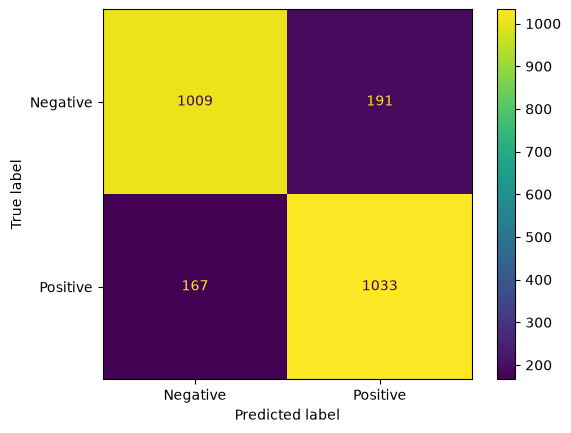

In [25]:
cm = confusion_matrix(y_test, y_pred_tfidf)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["Negative", "Positive"]
)

disp.plot()

## 13. Training Word2Vec Model

In [26]:
from gensim.models import Word2Vec
from nltk.tokenize import word_tokenize

# Tokenize the training reviews
X_train_tokens = [
    word_tokenize(text)
    for text in X_train
]

# Train Word2Vec only on training data
word2vec_model = Word2Vec(
    sentences=X_train_tokens,
    vector_size=100,
    window=5,
    min_count=2,
    workers=4,
    sg=1,
    epochs=10
)

print("Word2Vec vocabulary size:", len(word2vec_model.wv))

Word2Vec vocabulary size: 14563


## 14. Converting Reviews into Word2Vec Vectors

In [27]:
import numpy as np

def document_vector(text, model):
    words = word_tokenize(text)
    
    vectors = [
        model.wv[word]
        for word in words
        if word in model.wv
    ]
    
    if len(vectors) == 0:
        return np.zeros(model.vector_size)
    
    return np.mean(vectors, axis=0)


# Convert training and testing reviews
X_train_w2v = np.array([
    document_vector(text, word2vec_model)
    for text in X_train
])

X_test_w2v = np.array([
    document_vector(text, word2vec_model)
    for text in X_test
])

print("Training shape:", X_train_w2v.shape)
print("Testing shape:", X_test_w2v.shape)

Training shape: (9600, 100)
Testing shape: (2400, 100)


## 15. Training Logistic Regression with Word2Vec

In [28]:
from sklearn.linear_model import LogisticRegression

model_w2v = LogisticRegression(
    max_iter=1000,
    random_state=42
)

model_w2v.fit(X_train_w2v, y_train)

print("Word2Vec Logistic Regression model trained successfully.")

Word2Vec Logistic Regression model trained successfully.


## 16. Evaluating the Word2Vec Model

In [29]:
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay
)

# Make predictions
y_pred_w2v = model_w2v.predict(X_test_w2v)

# Accuracy
accuracy_w2v = accuracy_score(y_test, y_pred_w2v)

print("Word2Vec Accuracy:", accuracy_w2v)

Word2Vec Accuracy: 0.8483333333333334


In [30]:
print("Classification Report:")
print(classification_report(
    y_test,
    y_pred_w2v,
    target_names=["Negative", "Positive"]
))

Classification Report:
              precision    recall  f1-score   support

    Negative       0.84      0.85      0.85      1200
    Positive       0.85      0.84      0.85      1200

    accuracy                           0.85      2400
   macro avg       0.85      0.85      0.85      2400
weighted avg       0.85      0.85      0.85      2400



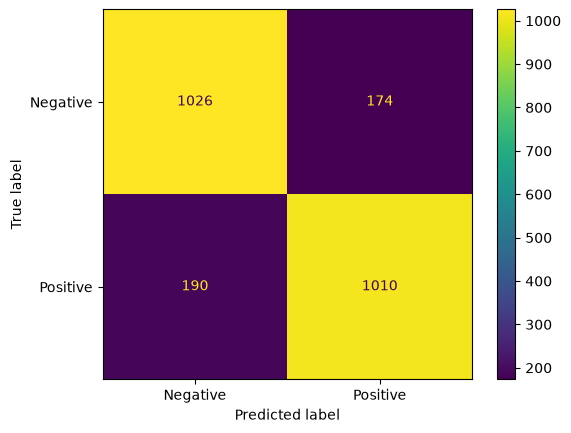

In [31]:
cm_w2v = confusion_matrix(y_test, y_pred_w2v)

disp_w2v = ConfusionMatrixDisplay(
    confusion_matrix=cm_w2v,
    display_labels=["Negative", "Positive"]
)

disp_w2v.plot()

## 17. Comparing TF-IDF and Word2Vec

In [32]:
comparison = pd.DataFrame({
    "Model": ["TF-IDF", "Word2Vec"],
    "Accuracy": [accuracy, accuracy_w2v]
})

comparison

,Model,Accuracy
0,TF-IDF,0.850833
1,Word2Vec,0.848333


### 18.selecting the best model

We compared TF-IDF and Word2Vec with Logistic Regression.

TF-IDF achieved 85.08% accuracy, while Word2Vec achieved 84.83%.

Therefore, we selected TF-IDF + Logistic Regression for deployment because it performed slightly better on our dataset.

### 18. predictive function

In [33]:
def preprocess_text(text):
    # Remove HTML
    review = BeautifulSoup(text, "html.parser").get_text()

    # Remove URLs
    review = re.sub(r"http\S+|www\S+", " ", review)

    # Keep only alphabets
    review = re.sub(r"[^a-zA-Z]", " ", review)

    # Lowercase
    review = review.lower()

    # Tokenize
    review = word_tokenize(review)

    # Remove stopwords + lemmatize
    review = [
        lemma.lemmatize(word)
        for word in review
        if word not in stop_words
    ]

    # Join words
    review = " ".join(review)

    # Remove extra spaces
    review = " ".join(review.split())

    return review

In [34]:
def predict_sentiment(review):
    # Preprocess the new review
    clean_review = preprocess_text(review)

    # Convert the review into TF-IDF features
    review_vector = tfidf.transform([clean_review])

    # Predict sentiment
    prediction = model_tfidf.predict(review_vector)[0]

    if prediction == 1:
        return "Positive"
    else:
        return "Negative"

In [35]:
review = "This book was amazing and I really enjoyed reading it."

print(predict_sentiment(review))

Positive


In [36]:
data.head()

,text,rating,sentiment,clean_text
0,Entertaining But Average Jace Rankin may be sh...,3,0,entertaining average jace rankin may short not...
1,Terrific menage scenes! Great short read. I d...,5,1,terrific menage scene great short read want pu...
2,Snapdragon Alley I'll start by saying this is ...,3,0,snapdragon alley start saying first four book ...
3,very light murder cozy Aggie is Angela Lansbur...,3,0,light murder cozy aggie angela lansbury carry ...
4,Book I did not expect this type of book to be ...,4,1,book not expect type book library pleased find...


In [38]:
data['clean_text'][24]

'shss story secret gave half way much repetition much make sense hard follow'

In [39]:
review1=data['clean_text'][24]
print(predict_sentiment(review1))

Negative


In [40]:
data['sentiment'][24]

np.int64(0)